# Vision Transformer (ViT) from Scratch — CIFAR-10

A Vision Transformer implemented **from scratch in PyTorch** (no `timm`, no pretrained
models) and trained on CIFAR-10.

**Architecture built from first principles:**
- Patch embedding via strided convolution
- Learnable `[CLS]` token + positional embeddings
- Multi-head self-attention
- Transformer encoder blocks (pre-norm, residual connections, GELU MLP)
- Full ViT assembly + training loop

**Result:** 683K-parameter model → **75% test accuracy** on CIFAR-10 (20 epochs, AdamW + augmentation).


## 1. Imports

In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T
from torch.utils.data import DataLoader

print("PyTorch:", torch.__version__, "| CUDA available:", torch.cuda.is_available())

PyTorch: 2.11.0+cu130 | CUDA available: True


## 2. Patch Embedding

Splits a 32×32 image into 4×4 patches (64 patches) using a strided conv that also
projects each patch to a 96-dim embedding. Prepends a learnable `[CLS]` token and adds
learnable positional embeddings, giving a sequence of 65 tokens.

In [8]:
class PatchEmbedding(nn.Module):
    def __init__(self, img_size=32, patch_size=4, in_channels=3, embed_dim=96):
        super().__init__()
        self.num_patches = (img_size // patch_size) ** 2
        # Strided conv: cuts image into non-overlapping patches AND projects them
        self.proj = nn.Conv2d(in_channels, embed_dim,
                              kernel_size=patch_size, stride=patch_size)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, self.num_patches + 1, embed_dim))

    def forward(self, x):
        B = x.shape[0]
        x = self.proj(x).flatten(2).transpose(1, 2)   # (B, 64, 96)
        cls = self.cls_token.expand(B, -1, -1)         # (B, 1, 96)
        x = torch.cat([cls, x], dim=1)                 # (B, 65, 96)
        x = x + self.pos_embed                         # add positional info
        return x


# Sanity check
pe = PatchEmbedding()
print(pe(torch.randn(2, 3, 32, 32)).shape)   # expect (2, 65, 96)

torch.Size([2, 65, 96])


## 3. Multi-Head Self-Attention

Scaled dot-product attention split across 4 heads. Q, K, V are produced by a single
fused linear layer, reshaped into heads, attention is computed per head, then heads are
merged and projected back to the embedding dimension.

`Attention(Q, K, V) = softmax(QKᵀ / √d_k) · V`

In [9]:
class MultiHeadAttention(nn.Module):
    def __init__(self, embed_dim=96, num_heads=4):
        super().__init__()
        assert embed_dim % num_heads == 0, "embed_dim must be divisible by num_heads"
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads          # 96 / 4 = 24
        self.qkv = nn.Linear(embed_dim, embed_dim * 3)  # Q, K, V in one layer
        self.proj = nn.Linear(embed_dim, embed_dim)
        self.attn_weights = None  # populated each forward pass (for visualization)     # final projection

    def forward(self, x):
        B, N, C = x.shape
        qkv = self.qkv(x).reshape(B, N, 3, self.num_heads, self.head_dim)
        qkv = qkv.permute(2, 0, 3, 1, 4)                # (3, B, heads, N, head_dim)
        q, k, v = qkv[0], qkv[1], qkv[2]

        scores = (q @ k.transpose(-2, -1)) / (self.head_dim ** 0.5)  # (B, heads, N, N)
        weights = F.softmax(scores, dim=-1)
        self.attn_weights = weights.detach()
        out = weights @ v                               # (B, heads, N, head_dim)

        out = out.transpose(1, 2).reshape(B, N, C)      # merge heads -> (B, N, 96)
        return self.proj(out)


# Sanity check
mha = MultiHeadAttention()
print(mha(torch.randn(2, 65, 96)).shape)   # expect (2, 65, 96)

torch.Size([2, 65, 96])


## 4. Transformer Encoder Block

Pre-norm transformer block: LayerNorm → attention → residual, then
LayerNorm → MLP → residual. Shape is preserved so blocks can be stacked.

In [10]:
class TransformerBlock(nn.Module):
    def __init__(self, embed_dim=96, num_heads=4, mlp_ratio=4):
        super().__init__()
        self.norm1 = nn.LayerNorm(embed_dim)
        self.attn = MultiHeadAttention(embed_dim, num_heads)
        self.norm2 = nn.LayerNorm(embed_dim)
        hidden = embed_dim * mlp_ratio                  # 96 * 4 = 384
        self.mlp = nn.Sequential(
            nn.Linear(embed_dim, hidden),
            nn.GELU(),
            nn.Linear(hidden, embed_dim),
        )

    def forward(self, x):
        x = x + self.attn(self.norm1(x))                # attention + residual
        x = x + self.mlp(self.norm2(x))                 # MLP + residual
        return x


# Sanity check
block = TransformerBlock()
print(block(torch.randn(2, 65, 96)).shape)   # expect (2, 65, 96)

torch.Size([2, 65, 96])


## 5. Full Vision Transformer

Assembles the pieces: patch embedding → stack of 6 transformer blocks → LayerNorm →
read the `[CLS]` token → linear classification head producing 10 class logits.

In [11]:
class VisionTransformer(nn.Module):
    def __init__(self, img_size=32, patch_size=4, in_channels=3,
                 embed_dim=96, num_heads=4, depth=6, num_classes=10):
        super().__init__()
        self.patch_embed = PatchEmbedding(img_size, patch_size, in_channels, embed_dim)
        self.blocks = nn.ModuleList([
            TransformerBlock(embed_dim, num_heads) for _ in range(depth)
        ])
        self.norm = nn.LayerNorm(embed_dim)
        self.head = nn.Linear(embed_dim, num_classes)

    def forward(self, x):
        x = self.patch_embed(x)
        for block in self.blocks:
            x = block(x)
        x = self.norm(x)
        cls = x[:, 0]                                   # take CLS token
        return self.head(cls)


model = VisionTransformer()
print("Output shape:", model(torch.randn(2, 3, 32, 32)).shape)   # expect (2, 10)
n_params = sum(p.numel() for p in model.parameters())
print(f"{n_params:,} parameters")

Output shape: torch.Size([2, 10])
683,242 parameters


## 6. Data — CIFAR-10

Training set uses augmentation (random crop + horizontal flip); test set is kept clean.
Both are normalized with CIFAR-10 channel statistics.

> **Note:** set `DATA_ROOT` to the folder containing `cifar-10-batches-py`.
> On Kaggle, attach the *CIFAR-10 Python* dataset and use its input path;
> locally, set `download=True`.

In [12]:
# Kaggle: point to the attached CIFAR-10 dataset. Locally: use './data' with download=True.
DATA_ROOT = './data'
DOWNLOAD = True

train_tf = T.Compose([
    T.RandomCrop(32, padding=4),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
    T.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)),
])
test_tf = T.Compose([
    T.ToTensor(),
    T.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)),
])

train_ds = torchvision.datasets.CIFAR10(root=DATA_ROOT, train=True,  download=DOWNLOAD, transform=train_tf)
test_ds  = torchvision.datasets.CIFAR10(root=DATA_ROOT, train=False, download=DOWNLOAD, transform=test_tf)

train_loader = DataLoader(train_ds, batch_size=128, shuffle=True,  num_workers=2)
test_loader  = DataLoader(test_ds,  batch_size=256, shuffle=False, num_workers=2)

print(f"Train batches: {len(train_loader)}, Test batches: {len(test_loader)}")

100%|██████████| 170M/170M [42:16<00:00, 67.2kB/s]


Train batches: 391, Test batches: 40


## 7. Training Setup

In [13]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = VisionTransformer().to(device)

criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.05)

# Sanity check: untrained loss should be ~ln(10) = 2.30
images, labels = next(iter(train_loader))
images, labels = images.to(device), labels.to(device)
print(f"Device: {device}")
print(f"Initial loss: {criterion(model(images), labels).item():.4f}  (expect ~2.30)")

Device: cuda
Initial loss: 2.4488  (expect ~2.30)


## 8. Training Loop

Standard train/eval loops. Training accumulates loss and accuracy per epoch; evaluation
runs under `torch.no_grad()` in `eval()` mode.

In [14]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * images.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        loss = criterion(logits, labels)
        total_loss += loss.item() * images.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, correct / total


EPOCHS = 20
history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    te_loss, te_acc = evaluate(model, test_loader, criterion, device)
    history["train_loss"].append(tr_loss); history["train_acc"].append(tr_acc)
    history["test_loss"].append(te_loss);  history["test_acc"].append(te_acc)
    print(f"Epoch {epoch:2d} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | "
          f"test loss {te_loss:.3f} acc {te_acc:.3f}")

print(f"\nBest test accuracy: {max(history['test_acc']):.3f}")

Epoch  1 | train loss 1.780 acc 0.338 | test loss 1.569 acc 0.433
Epoch  2 | train loss 1.441 acc 0.475 | test loss 1.337 acc 0.516
Epoch  3 | train loss 1.282 acc 0.533 | test loss 1.281 acc 0.544
Epoch  4 | train loss 1.187 acc 0.571 | test loss 1.142 acc 0.587
Epoch  5 | train loss 1.113 acc 0.603 | test loss 1.102 acc 0.610
Epoch  6 | train loss 1.061 acc 0.621 | test loss 1.054 acc 0.626
Epoch  7 | train loss 1.001 acc 0.643 | test loss 0.964 acc 0.656
Epoch  8 | train loss 0.954 acc 0.661 | test loss 0.943 acc 0.664
Epoch  9 | train loss 0.921 acc 0.673 | test loss 0.904 acc 0.680
Epoch 10 | train loss 0.880 acc 0.687 | test loss 0.895 acc 0.683
Epoch 11 | train loss 0.850 acc 0.699 | test loss 0.856 acc 0.692
Epoch 12 | train loss 0.822 acc 0.708 | test loss 0.834 acc 0.706
Epoch 13 | train loss 0.786 acc 0.723 | test loss 0.812 acc 0.707
Epoch 14 | train loss 0.766 acc 0.729 | test loss 0.790 acc 0.724
Epoch 15 | train loss 0.739 acc 0.739 | test loss 0.770 acc 0.726
Epoch 16 |

## 9. Training Curves

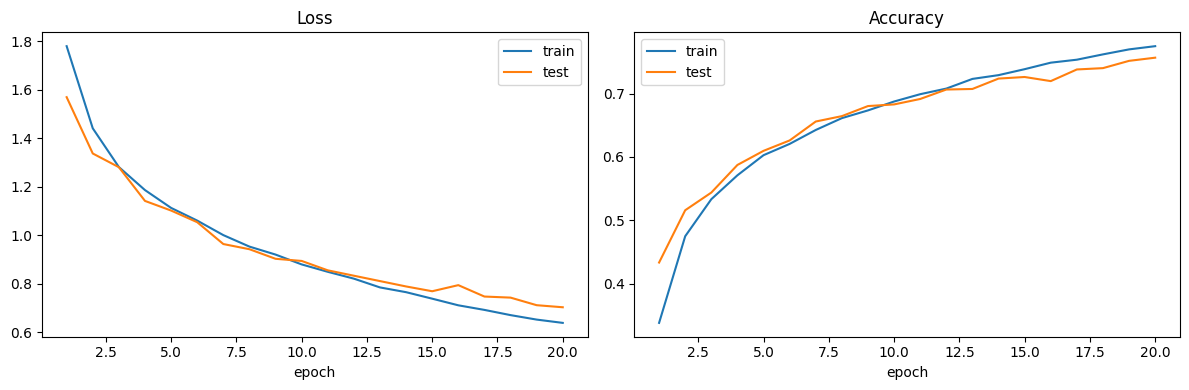

In [15]:
import matplotlib.pyplot as plt

epochs_range = range(1, EPOCHS + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(epochs_range, history["train_loss"], label="train")
ax1.plot(epochs_range, history["test_loss"], label="test")
ax1.set_title("Loss"); ax1.set_xlabel("epoch"); ax1.legend()

ax2.plot(epochs_range, history["train_acc"], label="train")
ax2.plot(epochs_range, history["test_acc"], label="test")
ax2.set_title("Accuracy"); ax2.set_xlabel("epoch"); ax2.legend()

plt.tight_layout()
plt.savefig("training_curves.png", dpi=120)
plt.show()

## 10. CNN Baseline (ResNet-18)

A convolutional baseline trained under identical settings, for a fair head-to-head
comparison. ResNet-18 is adapted for 32×32 inputs (a 3×3 stride-1 first conv and no initial
maxpool) so it doesn't destroy detail on small CIFAR images.


In [16]:
import torchvision.models as models

def make_cnn_baseline():
    m = models.resnet18(weights=None, num_classes=10)
    m.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
    m.maxpool = nn.Identity()
    return m

cnn = make_cnn_baseline().to(device)
cnn_optimizer = torch.optim.AdamW(cnn.parameters(), lr=3e-4, weight_decay=0.05)
print(f"CNN baseline: {sum(p.numel() for p in cnn.parameters()):,} parameters")

EPOCHS = 20
cnn_best = 0
for epoch in range(1, EPOCHS + 1):
    train_one_epoch(cnn, train_loader, criterion, cnn_optimizer, device)
    _, te_acc = evaluate(cnn, test_loader, criterion, device)
    cnn_best = max(cnn_best, te_acc)
    print(f"Epoch {epoch:2d} | test acc {te_acc:.3f}")

print(f"\nCNN best test accuracy: {cnn_best:.3f}")

CNN baseline: 11,173,962 parameters
Epoch  1 | test acc 0.562
Epoch  2 | test acc 0.677
Epoch  3 | test acc 0.651
Epoch  4 | test acc 0.803
Epoch  5 | test acc 0.775
Epoch  6 | test acc 0.827
Epoch  7 | test acc 0.818
Epoch  8 | test acc 0.831
Epoch  9 | test acc 0.830
Epoch 10 | test acc 0.856
Epoch 11 | test acc 0.856
Epoch 12 | test acc 0.853
Epoch 13 | test acc 0.865
Epoch 14 | test acc 0.867
Epoch 15 | test acc 0.868
Epoch 16 | test acc 0.877
Epoch 17 | test acc 0.871
Epoch 18 | test acc 0.870
Epoch 19 | test acc 0.873
Epoch 20 | test acc 0.893

CNN best test accuracy: 0.893


## 11. Ablation Studies

A small helper trains a fresh model for a fixed number of epochs and returns best test
accuracy. All ablations use a consistent 10 epochs for fair within-study comparison (fewer
than the headline run, so these numbers are not directly comparable to it).


In [17]:
def train_model(model, epochs=10):
    model = model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.05)
    best_acc = 0
    for _ in range(epochs):
        train_one_epoch(model, train_loader, criterion, opt, device)
        _, te_acc = evaluate(model, test_loader, criterion, device)
        best_acc = max(best_acc, te_acc)
    return best_acc

### Ablation 1 — Patch size

In [18]:
for ps in [2, 4, 8]:
    m = VisionTransformer(patch_size=ps)
    n_params = sum(p.numel() for p in m.parameters())
    num_patches = (32 // ps) ** 2
    acc = train_model(m, epochs=10)
    print(f"patch_size={ps} | {num_patches:3d} patches | {n_params:,} params | test acc {acc:.3f}")

patch_size=2 | 256 patches | 698,218 params | test acc 0.683
patch_size=4 |  64 patches | 683,242 params | test acc 0.692
patch_size=8 |  16 patches | 692,458 params | test acc 0.599


### Ablation 2 — Model depth

In [19]:
for d in [2, 6, 12]:
    m = VisionTransformer(depth=d)
    n_params = sum(p.numel() for p in m.parameters())
    acc = train_model(m, epochs=10)
    print(f"depth={d:2d} | {n_params:,} params | test acc {acc:.3f}")

depth= 2 | 235,882 params | test acc 0.628
depth= 6 | 683,242 params | test acc 0.689
depth=12 | 1,354,282 params | test acc 0.698


### Ablation 3 — Augmentation (strongest result)

Same model, with vs without augmentation. The telling number is the **train–test gap**:
without augmentation the model memorizes the training set (large gap); with it, train and
test track together.


In [20]:
train_tf_noaug = T.Compose([
    T.ToTensor(),
    T.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)),
])
train_ds_noaug = torchvision.datasets.CIFAR10(root=DATA_ROOT, train=True,
                                              download=DOWNLOAD, transform=train_tf_noaug)
train_loader_noaug = DataLoader(train_ds_noaug, batch_size=128, shuffle=True, num_workers=2)

def train_and_report_gap(model, loader, epochs=10):
    model = model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.05)
    for _ in range(epochs):
        _, tr_acc = train_one_epoch(model, loader, criterion, opt, device)
        _, te_acc = evaluate(model, test_loader, criterion, device)
    return tr_acc, te_acc

tr_a, te_a = train_and_report_gap(VisionTransformer(), train_loader, epochs=10)
print(f"WITH aug    | train {tr_a:.3f} | test {te_a:.3f} | gap {tr_a-te_a:+.3f}")
tr_n, te_n = train_and_report_gap(VisionTransformer(), train_loader_noaug, epochs=10)
print(f"WITHOUT aug | train {tr_n:.3f} | test {te_n:.3f} | gap {tr_n-te_n:+.3f}")

WITH aug    | train 0.678 | test 0.689 | gap -0.011
WITHOUT aug | train 0.762 | test 0.662 | gap +0.101


## 12. Attention-Map Visualization

To interpret the model, the `MultiHeadAttention` module stashes its softmax weights
(`self.attn_weights`). We read the last block's CLS-token attention and overlay it on the
image. (The attention module above already saves `attn_weights`; rebuild and train the model
after defining it so the weights are populated.)


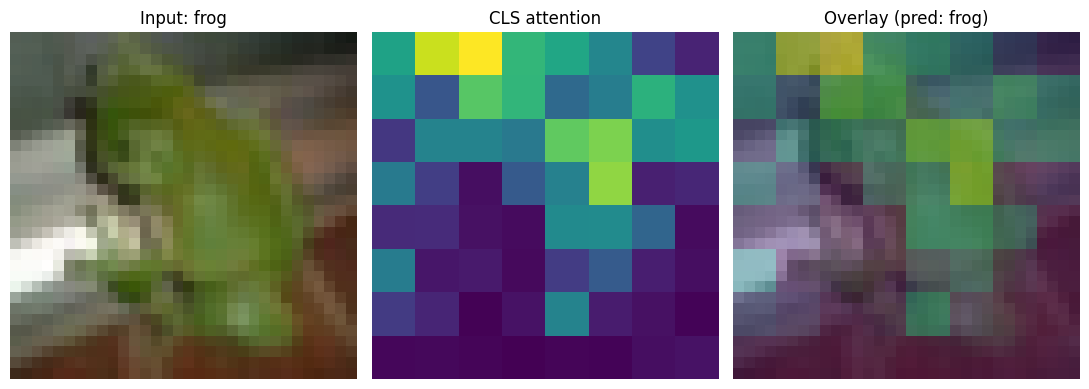

In [21]:
import matplotlib.pyplot as plt
import numpy as np

classes = ['plane','car','bird','cat','deer','dog','frog','horse','ship','truck']

model.eval()
img, label = test_ds[7]
with torch.no_grad():
    pred = model(img.unsqueeze(0).to(device)).argmax(1).item()

attn = model.blocks[-1].attn.attn_weights        # (1, heads, 65, 65)
cls_attn = attn[0].mean(0)[0, 1:].reshape(8, 8).cpu().numpy()

mean = np.array([0.4914, 0.4822, 0.4465]); std = np.array([0.2470, 0.2435, 0.2616])
img_disp = np.clip(img.permute(1, 2, 0).cpu().numpy() * std + mean, 0, 1)

fig, axes = plt.subplots(1, 3, figsize=(11, 4))
axes[0].imshow(img_disp);                  axes[0].set_title(f"Input: {classes[label]}")
axes[1].imshow(cls_attn, cmap='viridis');  axes[1].set_title("CLS attention")
axes[2].imshow(img_disp)
axes[2].imshow(np.kron(cls_attn, np.ones((4, 4))), cmap='viridis', alpha=0.5)
axes[2].set_title(f"Overlay (pred: {classes[pred]})")
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.savefig("attention_map.png", dpi=120); plt.show()

## 13. Stronger Model — Depth 12 + Cosine Schedule

The best result: a depth-12 model trained for 40 epochs with a cosine learning-rate
schedule reaches **~79.5%** test accuracy.


In [22]:
best_model = VisionTransformer(depth=12).to(device)
optimizer = torch.optim.AdamW(best_model.parameters(), lr=3e-4, weight_decay=0.05)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=40)

best = 0
for epoch in range(1, 41):
    train_one_epoch(best_model, train_loader, criterion, optimizer, device)
    _, te_acc = evaluate(best_model, test_loader, criterion, device)
    scheduler.step()
    best = max(best, te_acc)
    print(f"Epoch {epoch:2d} | test acc {te_acc:.3f} | best {best:.3f}")

print(f"\nBest test accuracy: {best:.3f}")
torch.save(best_model.state_dict(), "vit_best.pth")

Epoch  1 | test acc 0.417 | best 0.417
Epoch  2 | test acc 0.505 | best 0.505
Epoch  3 | test acc 0.554 | best 0.554
Epoch  4 | test acc 0.587 | best 0.587
Epoch  5 | test acc 0.617 | best 0.617
Epoch  6 | test acc 0.628 | best 0.628
Epoch  7 | test acc 0.662 | best 0.662
Epoch  8 | test acc 0.662 | best 0.662
Epoch  9 | test acc 0.676 | best 0.676
Epoch 10 | test acc 0.699 | best 0.699
Epoch 11 | test acc 0.700 | best 0.700
Epoch 12 | test acc 0.715 | best 0.715
Epoch 13 | test acc 0.728 | best 0.728
Epoch 14 | test acc 0.723 | best 0.728
Epoch 15 | test acc 0.747 | best 0.747
Epoch 16 | test acc 0.741 | best 0.747
Epoch 17 | test acc 0.753 | best 0.753
Epoch 18 | test acc 0.760 | best 0.760
Epoch 19 | test acc 0.770 | best 0.770
Epoch 20 | test acc 0.770 | best 0.770
Epoch 21 | test acc 0.773 | best 0.773
Epoch 22 | test acc 0.779 | best 0.779
Epoch 23 | test acc 0.777 | best 0.779
Epoch 24 | test acc 0.782 | best 0.782
Epoch 25 | test acc 0.780 | best 0.782
Epoch 26 | test acc 0.788

## 14. Real-World Images & Distribution Shift

Testing on real photos (not CIFAR). Center-crop preprocessing keeps the subject's aspect
ratio. The model does well on clean, in-distribution images and degrades on blurry/odd/
out-of-class ones — a distribution-shift limitation. Point `folder` at your own images.


In [23]:
from PIL import Image
import os

preprocess = T.Compose([
    T.Resize(36), T.CenterCrop(32), T.ToTensor(),
    T.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)),
])

folder = "/kaggle/input/your-images"   # <-- set to your uploaded images folder
if os.path.isdir(folder):
    img_paths = [os.path.join(folder, f) for f in os.listdir(folder)
                 if f.lower().endswith((".jpg", ".jpeg", ".png"))]
    best_model.eval()
    n = len(img_paths)
    fig, axes = plt.subplots(1, n, figsize=(3*n, 4))
    if n == 1: axes = [axes]
    for ax, path in zip(axes, img_paths):
        raw = Image.open(path).convert("RGB")
        x = preprocess(raw).unsqueeze(0).to(device)
        with torch.no_grad():
            probs = torch.softmax(best_model(x), dim=1)[0]
            pred = probs.argmax().item()
        ax.imshow(raw); ax.axis("off")
        ax.set_title(f"{classes[pred]} ({probs[pred]:.0%})", fontsize=10)
    plt.tight_layout(); plt.savefig("custom_predictions.png", dpi=120, bbox_inches="tight"); plt.show()
else:
    print("Set `folder` to a directory of images to run this cell.")

Set `folder` to a directory of images to run this cell.
